In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)
# Import data
all_sheets = pd.read_excel(r"C:\Users\Data Center\Documents\Traffic-Analysis\data\traffic_raw.xlsx", sheet_name=None)

In [132]:
# Check sheet names and preview data
print(all_sheets.keys()) # Show sheet names
print(all_sheets["Sheet2"].head())

dict_keys(['Sheet1', 'Sheet2'])
    NO                       STATION               DATE  UNKNOWN  \
0  NaN                           NaN                NaN      NaN   
1  1.0                 AHERO-KERICHO  10th/January/2026   1436.0   
2  2.0                  AHERO-KISUMU  10th/January/2026    518.0   
3  3.0  ELDAMA RAVINE- ELDAMA RAVINE  10th/January/2026   1705.0   
4  4.0        ELDAMA RAVINE- ESAGERI  10th/January/2026    160.0   

   PASSENGER CAR  2 AXLES  3 AXLES  4 AXLES  5 AXLES  6 AXLES  7 AXLES  \
0            NaN      NaN      NaN      NaN      NaN      NaN      NaN   
1         3127.0   1787.0    132.0      3.0     96.0    479.0      3.0   
2         3049.0   2707.0    140.0      2.0     12.0    591.0      2.0   
3          112.0     38.0      2.0      NaN      NaN      NaN      NaN   
4          646.0     96.0     11.0      NaN      1.0      1.0      NaN   

   8 AXLES  BUSES 2 AXLES  BUSES 3 AXLES  TOTAL BUSES  \
0      NaN            NaN            NaN          NaN   


In [133]:
df1 = all_sheets["Sheet2"]

df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 21 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   NO                                    30 non-null     float64
 1   STATION                               31 non-null     object 
 2   DATE                                  30 non-null     object 
 3   UNKNOWN                               30 non-null     float64
 4   PASSENGER CAR                         30 non-null     float64
 5   2 AXLES                               30 non-null     float64
 6   3 AXLES                               30 non-null     float64
 7   4 AXLES                               23 non-null     float64
 8   5 AXLES                               22 non-null     float64
 9   6 AXLES                               25 non-null     float64
 10  7 AXLES                               22 non-null     float64
 11  8 AXLES              

In [134]:
# Clean data
print(df1.isna().sum())
print()

NO                                       8
STATION                                  7
DATE                                     8
UNKNOWN                                  8
PASSENGER CAR                            8
2 AXLES                                  8
3 AXLES                                  8
4 AXLES                                 15
5 AXLES                                 16
6 AXLES                                 13
7 AXLES                                 16
8 AXLES                                 38
BUSES 2 AXLES                           13
BUSES 3 AXLES                           17
TOTAL BUSES                             13
AXLE VEHICLE WEIGHT OVERLOADS           10
GROSS VEHICLE WEIGHT OVERLOAD>0<2000     8
GROSS VEHICLE WEIGHT OVERLOAD>=2000     15
NO GROSS VEHICLE WEIGHT OVERLOADS        8
GROSS VEHICLE WEIGHT COMPLIANCE(%)       8
TOTAL TRAFFIC                            8
dtype: int64



In [135]:
for sheet_name, df1 in all_sheets.items():
    # Fill numeric columns with 0
    numeric_cols = df1.select_dtypes(include='number').columns
    df1[numeric_cols] = df1[numeric_cols].fillna(0)
    df1[numeric_cols] = df1[numeric_cols].astype(float)

    # Fill object/text columns with "Unknown"
    text_cols = df1.select_dtypes(include='object').columns
    df1[text_cols] = df1[text_cols].fillna("Unknown")
    all_sheets[sheet_name] = df1 #update dictionary

In [136]:
print(df1.isna().sum())

# Clean columns
df1.columns = df1.columns.str.strip().str.replace(" " , "_")

type(df1)

NO                                      0
STATION                                 0
DATE                                    0
UNKNOWN                                 0
PASSENGER CAR                           0
2 AXLES                                 0
3 AXLES                                 0
4 AXLES                                 0
5 AXLES                                 0
6 AXLES                                 0
7 AXLES                                 0
8 AXLES                                 0
BUSES 2 AXLES                           0
BUSES 3 AXLES                           0
TOTAL BUSES                             0
AXLE VEHICLE WEIGHT OVERLOADS           0
GROSS VEHICLE WEIGHT OVERLOAD>0<2000    0
GROSS VEHICLE WEIGHT OVERLOAD>=2000     0
NO GROSS VEHICLE WEIGHT OVERLOADS       0
GROSS VEHICLE WEIGHT COMPLIANCE(%)      0
TOTAL TRAFFIC                           0
dtype: int64


pandas.core.frame.DataFrame

In [137]:
df1["DATE"] = pd.to_datetime(df1["DATE"], errors="coerce")
df1["STATION"] = df1["STATION"].astype(str)

C:\Users\Data Center\AppData\Local\Temp\ipykernel_15088\2056240888.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df1["DATE"] = pd.to_datetime(df1["DATE"], errors="coerce")


In [138]:
# Executive summary
# Total traffic summary
Total_Traffic = df1["TOTAL_TRAFFIC"].sum()
Passenger_Cars = df1["PASSENGER_CAR"].sum()
Trucks = df1[["2_AXLES", "3_AXLES", "4_AXLES", "5_AXLES", "6_AXLES", "7_AXLES", "8_AXLES"]].sum().sum()
Buses  = df1[["BUSES_2_AXLES", "BUSES_3_AXLES"]].sum().sum()
Unknown = df1["UNKNOWN"].sum()

# Count relative to total traffic
Passenger_perc = Passenger_Cars/Total_Traffic * 100
Trucks_perc = Trucks/Total_Traffic * 100
Buses_perc = Buses/Total_Traffic * 100
Unknown_perc = Unknown/Total_Traffic * 100

# Description
print("1.0 Executive Summary", 1)
print("1.1 Total Traffic Summary")
print(
    f"Total number of vehicles weighed across the stations:{int(Total_Traffic):,}")
print(f"Passenger cars:{int(Passenger_Cars):,} ({Passenger_perc:.2f}%)")
print(f"Trucks:{int(Trucks):,} ({Trucks_perc:.2f})%")
print(f"Total number of unknown vehicles:{int(Unknown):,} ({Unknown_perc:.2f})%")
print(f"Buses:{int(Buses):,} ({Buses_perc:.2f}%)\n")

# Total Traffic Summary
Traffic_Summary = pd.DataFrame({"Number of vehicles":[Unknown, Passenger_Cars, Trucks, Buses, Total_Traffic],
                                "Count relative to total traffic (%)": [Unknown_perc, Passenger_perc, Trucks_perc, Buses_perc, 100.0] 
                                }, index=["Unknown", "Passenger Cars", "Trucks", "Buses", "Total Traffic"])

print("Table 1: Total Traffic Summary for all virtual stations")
print(Traffic_Summary.to_string(
    formatters={"Number of vehicles": '{:.0f}'.format, 
                "Count relative to total traffic (%)": "{:.2f}".format}
                ))
print("\n") # Blank line betweeb tables

# Overloads summary
df1.rename(columns={"GROSS_VEHICLE_WEIGHT_OVERLOAD>0<2000":"GROSS_VEHICLE_WEIGHT_OVERLOAD_0_2000"}, inplace=True)
df1.rename(columns={"GROSS_VEHICLE_WEIGHT_OVERLOAD>=2000":"GROSS_VEHICLE_WEIGHT_OVERLOAD_2000"}, inplace=True)
Gross_Vehicle_Weight_overload_0_2000 = df1["GROSS_VEHICLE_WEIGHT_OVERLOAD_0_2000"].sum()
Gross_Vehicle_Weight_overload_2000 = df1["GROSS_VEHICLE_WEIGHT_OVERLOAD_2000"].sum()
No_Gross_Vehicle_Gross_Vehicle_Weight_overload = df1["NO_GROSS_VEHICLE_WEIGHT_OVERLOADS"].sum()

#Count relative to total traffic
Gross_Vehicle_Weight_overload_0_2000_perc = Gross_Vehicle_Weight_overload_0_2000/Total_Traffic * 100
Gross_Vehicle_Weight_overload_2000_perc = Gross_Vehicle_Weight_overload_2000/Total_Traffic * 100
No_Gross_Vehicle_Gross_Vehicle_Weight_overload_perc = No_Gross_Vehicle_Gross_Vehicle_Weight_overload/Total_Traffic * 100

Overloads_Summary = pd.DataFrame({"Number of vehicles": [Gross_Vehicle_Weight_overload_0_2000, Gross_Vehicle_Weight_overload_2000, No_Gross_Vehicle_Gross_Vehicle_Weight_overload, Total_Traffic],
                                  "Count relative to total traffic (%)": [Gross_Vehicle_Weight_overload_0_2000_perc, Gross_Vehicle_Weight_overload_2000_perc, No_Gross_Vehicle_Gross_Vehicle_Weight_overload_perc, 100.0]
                                   }, index=["Gross Vehicle Weight overload>0<2000", "Gross Vehicle Weight overload>=2000", "No Gross Vehicle Gross Vehicle Weight overload", "Total Traffic"])
print("1.2 Overloads Summary")
print(f"Gross vehicle weight overload between 0 and 2,000kg:{int(Gross_Vehicle_Weight_overload_0_2000):,} ({Gross_Vehicle_Weight_overload_0_2000_perc:.2f})%")
print(f"Gross vehicle weight overload exceeding 2,000kg:{int(Gross_Vehicle_Weight_overload_2000):,} ({Gross_Vehicle_Weight_overload_2000_perc:.2f})%")
print(f"Compliance-Number of vehicles with no overload:{int(No_Gross_Vehicle_Gross_Vehicle_Weight_overload):,} ({No_Gross_Vehicle_Gross_Vehicle_Weight_overload_perc:.2f})%\n")
print("Table 2: Total Overloads Summary for All Stations")
print(Overloads_Summary.to_string(
    formatters={"Number of vehicles": '{:.0f}'.format, 
                "Count relative to total traffic (%)": '{:.2f}'.format}))



1.0 Executive Summary 1
1.1 Total Traffic Summary
Total number of vehicles weighed across the stations:119,203
Passenger cars:40,618 (34.07%)
Trucks:44,588 (37.41)%
Total number of unknown vehicles:31,860 (26.73)%
Buses:2,137 (1.79%)

Table 1: Total Traffic Summary for all virtual stations
               Number of vehicles Count relative to total traffic (%)
Unknown                     31860                               26.73
Passenger Cars              40618                               34.07
Trucks                      44588                               37.41
Buses                        2137                                1.79
Total Traffic              119203                              100.00


1.2 Overloads Summary
Gross vehicle weight overload between 0 and 2,000kg:3,439 (2.88)%
Gross vehicle weight overload exceeding 2,000kg:3,068 (2.57)%
Compliance-Number of vehicles with no overload:112,696 (94.54)%

Table 2: Total Overloads Summary for All Stations
                      

In [139]:
# List of all stations that should have data
expected_stations = [
    "Ahero", "Eldama Ravine", "Eldoret", "Emali", "Kajiado", "Kaloleni", "Kamulu", "Kibwezi",  "Laisamis", "Madogo", "Makutano", "Malaba", "Malili", "Malindi", "Mayoni","Meru", "Mukumu", "Mwatate", "Ngeria", "Salgaa", "Southern Bypass", "Rongo","Yatta"
]
# Convert expected stations to uppercase
expected_stations_upper = [s.upper() for s in expected_stations]
df1["STATION_ORIGIN"] = df1["STATION"].str.split("-").str[0].str.strip()
# Get unique origin stations in the dataset
present_stations_upper = df1["STATION_ORIGIN"].unique().tolist()
missing_stations = [
    expected_stations[i] 
    for i, s in enumerate(expected_stations_upper)
    if s not in present_stations_upper
    ]
print("The following stations did not stream any data during the analysis period:\n")
for i, station in enumerate(missing_stations, 1):
    print(f"{i}.{station}")

The following stations did not stream any data during the analysis period:

1.Eldoret
2.Kamulu
3.Laisamis
4.Madogo
5.Makutano
6.Malaba
7.Mayoni
8.Rongo



2.0 Analysis of Total Traffic
2.1 Total Traffic per Station

• Southern Bypass recorded the highest traffic volume during the day, with 34,256 vehicles, accounting for 28.74% of the total traffic.
• Emali recorded the lowest traffic.



C:\Users\Data Center\AppData\Local\Temp\ipykernel_15088\336699208.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


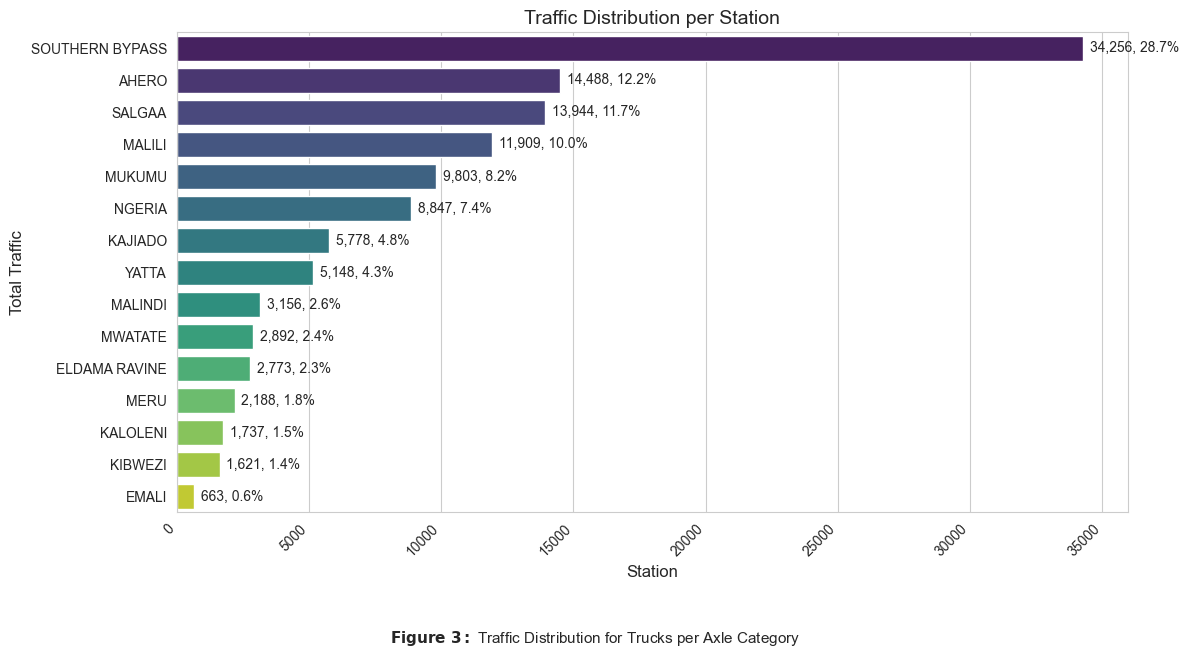

In [140]:
# Group by station and total traffic per station
traffic_per_station  = df1.groupby("STATION_ORIGIN")["TOTAL_TRAFFIC"].sum().reset_index()
# Sort by descending to find the highest and lowest

traffic_per_station = traffic_per_station[
    traffic_per_station['STATION_ORIGIN'].notna() & 
    (traffic_per_station['STATION_ORIGIN'].str.strip() !="") &
    (traffic_per_station['STATION_ORIGIN'].str.strip() !="0") &
    (traffic_per_station['STATION_ORIGIN'].str.strip().str.lower() != "unknown")
    ]
# Sort by TOTAL_TRAFFIC descending
traffic_per_station = traffic_per_station.sort_values(by="TOTAL_TRAFFIC", ascending=False).reset_index(drop=True)
# Calculate total traffic across all stations
total_traffic_all = traffic_per_station["TOTAL_TRAFFIC"].sum()
# Add traffic percentage column
traffic_per_station["Percentage"] = (traffic_per_station["TOTAL_TRAFFIC"]/total_traffic_all * 100).round(2)
# Station with highest traffic
highest = traffic_per_station.iloc[0]
lowest = traffic_per_station.iloc[-1]

summary_text = f"""
2.0 Analysis of Total Traffic
2.1 Total Traffic per Station

• {highest["STATION_ORIGIN"].title()} recorded the highest traffic volume during the day, with {int(highest['TOTAL_TRAFFIC']):,} vehicles, accounting for {highest['Percentage']}% of the total traffic.
• {lowest["STATION_ORIGIN"].title()} recorded the lowest traffic.
"""

print(summary_text)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=traffic_per_station,
    y="STATION_ORIGIN",
    x="TOTAL_TRAFFIC",
    palette="viridis"  
)
# Add total traffic + percentage labels above each bar
for p, (_, row) in zip(ax.patches, traffic_per_station.iterrows()):
    total = row["TOTAL_TRAFFIC"]
    perc = row["Percentage"]
    
    x =  p.get_width()  # bar length
    y = p.get_y() + p.get_height() / 2.  
    
    # Total traffic first, just above bar
    ax.annotate(
        f'{total:,.0f}, {perc:.1f}%',
        (x, y),  
        xytext=(5,0),   # shift right of bar
        textcoords='offset points',
        ha='left', 
        va='center',
        fontsize=10,
        )

plt.title("Traffic Distribution per Station", fontsize=14)
plt.xlabel("Station", fontsize=12)
plt.ylabel("Total Traffic", fontsize=12)

plt.xticks(rotation=45, ha='right')  # tilt labels for readability
plt.subplots_adjust(bottom=0.25)   # extra space for long labels





plt.figtext(
    0.5, -0.08,
    r"$\bf{Figure\ 3:}$ Traffic Distribution for Trucks per Axle Category",
    ha="center",
    fontsize=11
)

plt.subplots_adjust(bottom=0.2)

plt.tight_layout()

plt.savefig("traffic.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()



2.2 Total Traffic per Vehicle Category
• The figure below represents the traffic distribution per vehicle category. Passenger cars had the highest frequency. 8 axles had no traffic record. The data shows that passenger cars, 2 axles and unidentified vehicles constitute a larger portion of traffic count.



C:\Users\Data Center\AppData\Local\Temp\ipykernel_15088\781409964.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


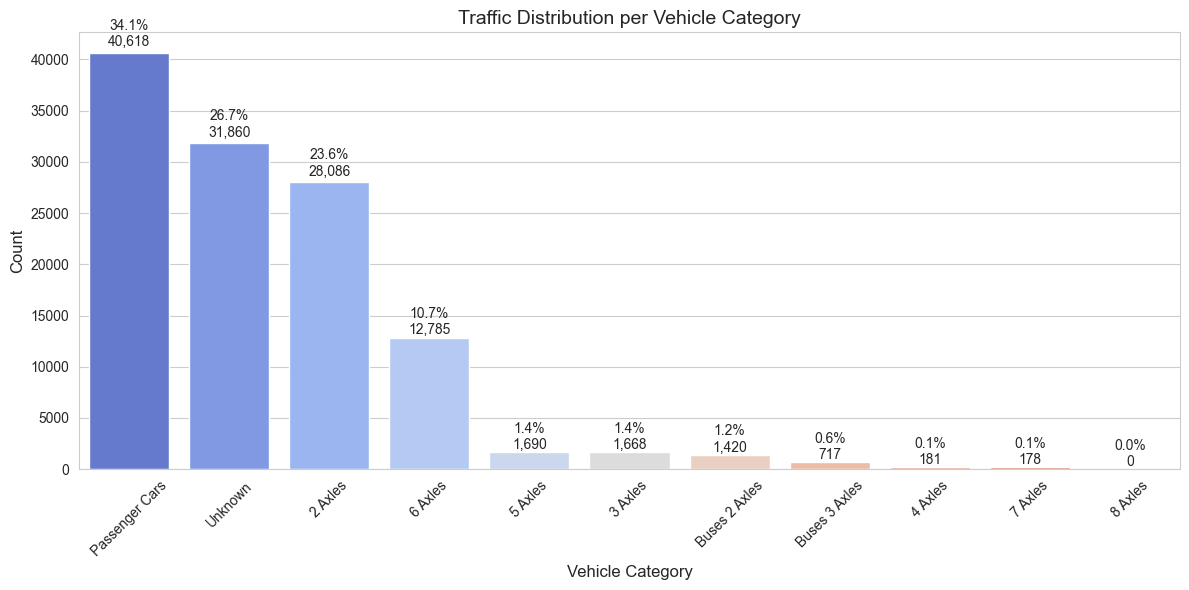

In [141]:
vehicle_category = {
    "Passenger Cars": Passenger_Cars,
    "2 Axles": df1["2_AXLES"].sum(),
    "3 Axles": df1["3_AXLES"].sum(),
    "4 Axles": df1["4_AXLES"].sum(),
    "5 Axles": df1["5_AXLES"].sum(),
    "6 Axles": df1["6_AXLES"].sum(),
    "7 Axles": df1["7_AXLES"].sum(),
    "8 Axles": df1["8_AXLES"].sum(),
    "Buses 2 Axles": df1["BUSES_2_AXLES"].sum(),
    "Buses 3 Axles": df1["BUSES_3_AXLES"].sum(),
    "Unknown": Unknown
}
vehicle_df = pd.DataFrame(list(vehicle_category.items()), columns=["Category", "Count"])

# Total traffic
total = vehicle_df["Count"].sum()

# Add percentage column
vehicle_df["Percentage"] = (vehicle_df["Count"] / total * 100) .round(2)
# Sort descending
vehicle_df = vehicle_df.sort_values(by="Count", ascending=False)

summary_text = f"""
2.2 Total Traffic per Vehicle Category
• The figure below represents the traffic distribution per vehicle category. Passenger cars had the highest frequency. 8 axles had no traffic record. The data shows that passenger cars, 2 axles and unidentified vehicles constitute a larger portion of traffic count.
"""
print(summary_text)

plt.figure(figsize=(12,6))

ax = sns.barplot(
data=vehicle_df,
x="Category",
y="Count",
palette="coolwarm"
)

# Add annotations
for  p, (_,row) in zip(ax.patches, vehicle_df.iterrows()):
    height = p.get_height()
    perc = row["Percentage"]
    
    ax.text(
        p.get_x() + p.get_width()/2,
        height + (height * 0.01),   # small offset above bar
        f'{perc:.1f}%\n{int(height):,}',
        ha='center',
        va='bottom',
        fontsize=10
)

plt.title("Traffic Distribution per Vehicle Category", fontsize=14)
plt.xlabel("Vehicle Category", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("category.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()



                                                                


2.3 Total Traffic for Trucks per Axle Configuration

The table below shows the distribution of trucks traffic during the day. 2 Axles had the highest record followed by 6 Axle trucks, indicating a mix of light and heavy freight movement.



Table3: Trucks Traffic Distribution per Axle Configuration


Table3: Trucks Traffic Distribution per Axle Configuration

Axle Configuration Total Count Percentage
            2 Axle     28086.0      63.0%
            6 Axle     12785.0      28.7%
            5 Axle      1690.0       3.8%
            3 Axle      1668.0       3.7%
            4 Axle       181.0       0.4%
            7 Axle       178.0       0.4%
            8 Axle           -       0.0%
      TOTAL TRUCKS     44588.0     100.0%


C:\Users\Data Center\AppData\Local\Temp\ipykernel_15088\3061171946.py:59: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  plot_df["Total Count"] = plot_df["Total Count"].replace("-", 0).astype(float)


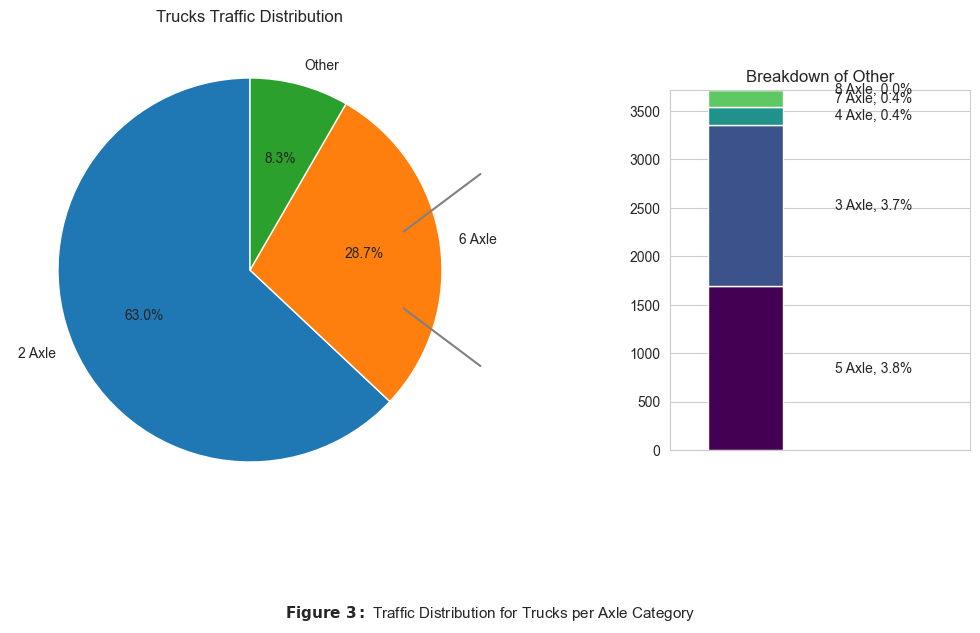

In [142]:
trucks_axles = {
    "2 Axle":df1["2_AXLES"].sum(),
    "3 Axle":df1["3_AXLES"].sum(),
    "4 Axle":df1["4_AXLES"].sum(),
    "5 Axle":df1["5_AXLES"].sum(),
    "6 Axle":df1["6_AXLES"].sum(),
    "7 Axle":df1["7_AXLES"].sum(),
    "8 Axle":df1["8_AXLES"].sum(),
}

summary_text = f"""
2.3 Total Traffic for Trucks per Axle Configuration

The table below shows the distribution of trucks traffic during the day. 2 Axles had the highest record followed by 6 Axle trucks, indicating a mix of light and heavy freight movement.

"""

print(summary_text)

# Create DataFrame
trucks_df = pd.DataFrame(
    list(trucks_axles.items()), columns=["Axle Configuration", "Total Count"]
    )
    
print("\nTable3: Trucks Traffic Distribution per Axle Configuration\n")

# Calculate totals
total_trucks  = trucks_df["Total Count"].sum()
trucks_df["Percentage"] = (trucks_df["Total Count"] / total_trucks * 100).round(2)
# Sort descending
trucks_df = trucks_df.sort_values(by="Total Count", ascending=False)

# Replace 0 with dash for reporting
trucks_df["Total Count"] = trucks_df["Total Count"].replace(0,"-")

# Add total row
total_row = pd.DataFrame({
    "Axle Configuration": ["TOTAL TRUCKS"],
    "Total Count": [total_trucks],
    "Percentage": [100.0]
})

final_trucks_table = pd.concat([trucks_df,total_row], ignore_index=True)

print("\nTable3: Trucks Traffic Distribution per Axle Configuration\n")

print(final_trucks_table.to_string(
    index=False,
    formatters={
        "Total Count": lambda x: f"{int(x):,}" if isinstance(x, (int, float)) else x,
        "Percentage": "{:.1f}%".format
    }
))


#   Plot figure

plot_df = trucks_df.copy()
plot_df["Total Count"] = plot_df["Total Count"].replace("-", 0).astype(float)

labels = plot_df["Axle Configuration"]
sizes = plot_df["Total Count"]

# --- Split data ---
# Main categories
main_labels = []
main_sizes = []

# Small categories grouped as "Other"
other_labels = []
other_sizes = []

threshold = 5  # percentage threshold

total = sizes.sum()

for i in range(len(sizes)):
    pct = (sizes.iloc[i] / total) * 100
    if pct >= threshold:
        main_labels.append(labels.iloc[i])
        main_sizes.append(sizes.iloc[i])
    else:
        other_labels.append(labels.iloc[i])
        other_sizes.append(sizes.iloc[i])

# Add Other
main_labels.append("Other")
main_sizes.append(sum(other_sizes))

# --- Plot ---
fig = plt.figure(figsize=(12,6))

# Main pie
ax1 = fig.add_axes([0.05, 0.1, 0.5, 0.8])
wedges, texts, autotexts = ax1.pie(
    main_sizes,
    labels=main_labels,
    autopct='%1.1f%%',
    startangle=90
)

ax1.set_title("Trucks Traffic Distribution")

# Secondary bar (stacked)
ax2 = fig.add_axes([0.65, 0.2, 0.25, 0.6])

bottom = 0
colors = plt.cm.viridis(np.linspace(0,1,len(other_sizes)))

for i in range(len(other_sizes)):
    ax2.bar(
        0,
        other_sizes[i],
        bottom=bottom,
        color=colors[i],
        width=0.5
    )
    y = bottom + other_sizes[i]/2
    pct = (other_sizes[i]/total)*100
    ax2.text(
        0.6,
        y,
        f"{other_labels[i]}, {pct:.1f}%",
        va='center'
    )
    bottom += other_sizes[i]

ax2.set_xlim(-0.5, 1.5)
ax2.set_xticks([])
ax2.set_title("Breakdown of Other")

# Connection lines (optional)
ax1.plot([0.8, 1.2], [0.2, 0.5], color='gray')
ax1.plot([0.8, 1.2], [-0.2, -0.5], color='gray')


plt.figtext(
    0.5, -0.08,
    r"$\bf{Figure\ 3:}$ Traffic Distribution for Trucks per Axle Category",
    ha="center",
    fontsize=11
)

plt.subplots_adjust(bottom=0.2)


plt.savefig("trucks.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


C:\Users\Data Center\AppData\Local\Temp\ipykernel_15088\936527084.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["Unknown_Percentage"] = (df1["UNKNOWN"] / df1["TOTAL_TRAFFIC"] * 100).round(-0)


3.0 Unknowns
• This section of the report analyzes the distribution of unknown vehicles across different stations. The data shows significant variation in the percentage of unknown vehicles, likely influenced by factors traffic flow, and the characteristics of the routes they serve. Recognizing these patterns is key to identifying areas that may need further investigation or targeted enforcement.
• A high percentage of unknown vehicles at specific stations may point to issues with ANPR camera performance or reflect the types of vehicles commonly used in those regions.
• Eldama Ravine-Eldama Ravine (92%) and Meru-Meru (67%) had the highest failure of the ANPR cameras in identifying vehicles. Other stations with high rate of unknowns were Southern Bypass-Mombasa (62%), Kibwezi-Kibwezi (42%) and Southern Bypass-Kikuyu (51%).


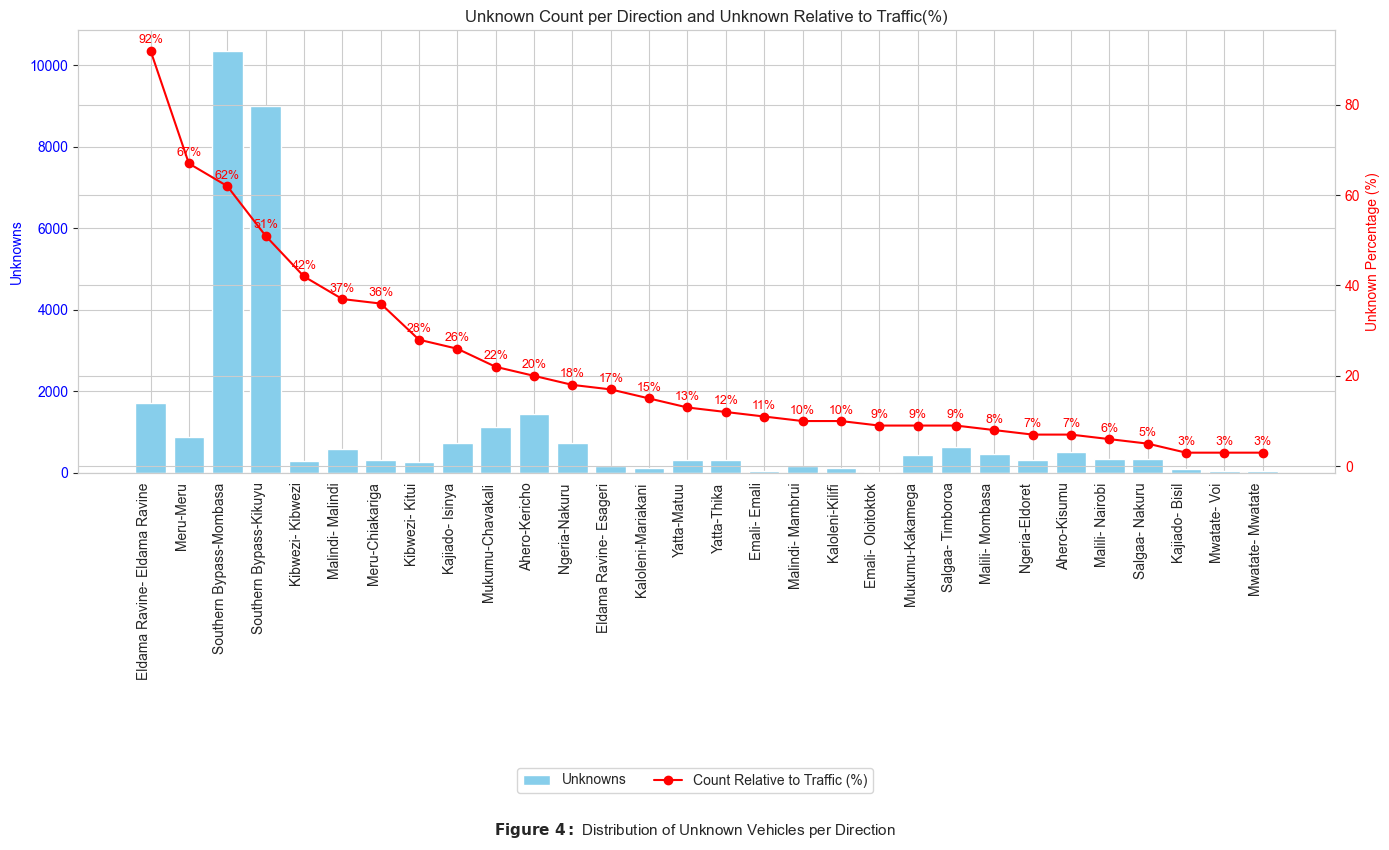

In [143]:
# Format station names
df1["STATION"] = df1["STATION"].astype(str).str.lower().str.title()
df1= df1[~df1["STATION"].str.strip().str.lower().isin(["unknown", "0"])]

# Calculate Unknown Percentage
df1["Unknown_Percentage"] = (df1["UNKNOWN"] / df1["TOTAL_TRAFFIC"] * 100).round(-0)
df1 = df1.sort_values(by="Unknown_Percentage", ascending=False)

# Plot figure
fig, ax1 = plt.subplots(figsize=(14, 7))

# Bar chart for Unknown counts
bars = ax1.bar(df1["STATION"], df1["UNKNOWN"], color="skyblue", label="Unknowns")

ax1.set_ylabel("Unknowns", color="blue")
ax1.tick_params(axis='y', labelcolor="blue")

plt.xticks(rotation=90, ha="right")

# Second axis for Unknown Percentages)
ax2 = ax1.twinx()
line = ax2.plot(df1["STATION"], df1["Unknown_Percentage"], color="red", marker="o", label="Count Relative to Traffic (%)")

ax2.set_ylabel("Unknown Percentage (%)", color="red")
ax2.tick_params(axis='y', labelcolor="red")

# Add labels on line points
for x, y in zip(df1["STATION"], df1["Unknown_Percentage"]):
    if pd.notna(y):   # Only add label if y is not NaN
        ax2.text(
        x, 
        y + 1, 
        f"{int(y)}%",   # convert to int to remove decimals
        color="red",
        ha='center',
        va='bottom', 
        fontsize=9
        )

# Move Legends below x-axis by placing them in figure's lower center
fig.legend(loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=2)

# Summary text
summary_text = (
  "3.0 Unknowns\n"
   "• This section of the report analyzes the distribution of unknown vehicles across different stations. "
   "The data shows significant variation in the percentage of unknown vehicles, likely influenced by factors "
   "traffic flow, and the characteristics of the routes they serve. Recognizing these patterns is key to "
   "identifying areas that may need further investigation or targeted enforcement.\n"
   "• A high percentage of unknown vehicles at specific stations may point to issues with ANPR camera performance "
   "or reflect the types of vehicles commonly used in those regions.\n"
   "• Eldama Ravine-Eldama Ravine (92%) and Meru-Meru (67%) had the highest failure of the ANPR cameras in identifying vehicles. "
   "Other stations with high rate of unknowns were Southern Bypass-Mombasa (62%), Kibwezi-Kibwezi (42%) "
   "and Southern Bypass-Kikuyu (51%)."
)

print(summary_text)

# Adjust layout to make room at the bottom
fig.subplots_adjust(bottom=0.25)   # Increase bottom margin

# Add figure caption 
fig.text(
    0.5,
    -0.20,
    r"$\bf{Figure\ 4:}$ Distribution of Unknown Vehicles per Direction",
    ha='center',
    fontsize=11
)


plt.title("Unknown Count per Direction and Unknown Relative to Traffic(%)")

plt.tight_layout()

plt.savefig("unknown.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

   

In [144]:

df1.columns = df1.columns.str.strip()
# Create Total Overloads column
df1["Total_Overloads"] = (
    df1["GROSS_VEHICLE_WEIGHT_OVERLOAD_0_2000"] + 
    df1["GROSS_VEHICLE_WEIGHT_OVERLOAD_2000"])

df1["Compliance"] = (1-(df1["Total_Overloads"] / df1["TOTAL_TRAFFIC"])) * 100

# Rename Columns
df1 = df1.rename(columns={
    "STATION": "Station",
    "Total_Overloads": "Total Overloads",
    "GROSS_VEHICLE_WEIGHT_OVERLOAD_0_2000": "GVW Overloads>0<2000",
    "GROSS_VEHICLE_WEIGHT_OVERLOAD_2000": "GVW Overloads>=2000",
    "AXLE_VEHICLE_WEIGHT_OVERLOADS":"AVW Overloads",
    "TOTAL_TRAFFIC": "Traffic"
})


# Create a table
table = df1[[
    "Station",
    "GVW Overloads>0<2000",
    "GVW Overloads>=2000",
    "Total Overloads",
    "AVW Overloads",
    "Compliance",
    "Traffic"
]]

# Compute totals
total_overloads = table["Total Overloads"].sum()
total_traffic = table["Traffic"].sum()

total_row = {
    "Station": "TOTAL",
    "GVW Overloads>0<2000": table["GVW Overloads>0<2000"].sum(),
    "GVW Overloads>=2000": table["GVW Overloads>=2000"].sum(),
    "Total Overloads": table["Total Overloads"].sum(),
    "AVW Overloads": table["AVW Overloads"].sum(),
    "Compliance": (1 - (total_overloads / total_traffic)) * 100,
    "Traffic": table["Traffic"].sum()
}

# Append total row
table = pd.concat([table, pd.DataFrame([total_row])], ignore_index=True)
table["Compliance"] = table["Compliance"].round(1).astype(str) + "%"


# Separate total row
total_row = table[table["Station"] == "TOTAL"]
data_rows = table[table["Station"] != "TOTAL"]

# Sort only data rows
data_rows = data_rows.sort_values(by="Total Overloads", ascending=False)
highest = data_rows.iloc[0]
second_highest = data_rows.iloc[1]

table = pd.concat([data_rows, total_row], ignore_index=True)
cols_to_int = [
    "GVW Overloads>0<2000",
    "GVW Overloads>=2000",
    "Total Overloads",
    "AVW Overloads",
    "Traffic"
]

table[cols_to_int] = table[cols_to_int].astype(int)
table[cols_to_int] = table[cols_to_int].map(lambda x: f"{x:,}")


summary_text = (
    "4.0 Analysis of Overloads_Summary\n"
    "•The table below represents the distributiono of gross vehicle weight, and axle vehicle weight overloads across the virtual stations, with percentage of compliance per direction.\n"
    )
    

print(summary_text)

# Display table neatly
pd.set_option('display.max_columns' , None)
print(table)

4.0 Analysis of Overloads_Summary
•The table below represents the distributiono of gross vehicle weight, and axle vehicle weight overloads across the virtual stations, with percentage of compliance per direction.

                         Station GVW Overloads>0<2000 GVW Overloads>=2000  \
0               Salgaa- Timboroa                  598               1,003   
1                Malili- Nairobi                  849                 522   
2                 Ngeria-Eldoret                  393                 263   
3                 Salgaa- Nakuru                  345                 173   
4                   Ahero-Kisumu                  264                 207   
5                Malili- Mombasa                  228                 150   
6                  Ngeria-Nakuru                  110                 230   
7                  Ahero-Kericho                  112                 169   
8         Southern Bypass-Kikuyu                  183                  22   
9        Souther


    4.1 Gross Vehicle Overloads per Station per Direction and Compliance
    • Salgaa- Timboroa recorded the highest number of gross vehicle weight overloads, totaling 1,601, followed by Malili- Nairobi with 1,371.
    • On average, the compliance rate was 94.5%



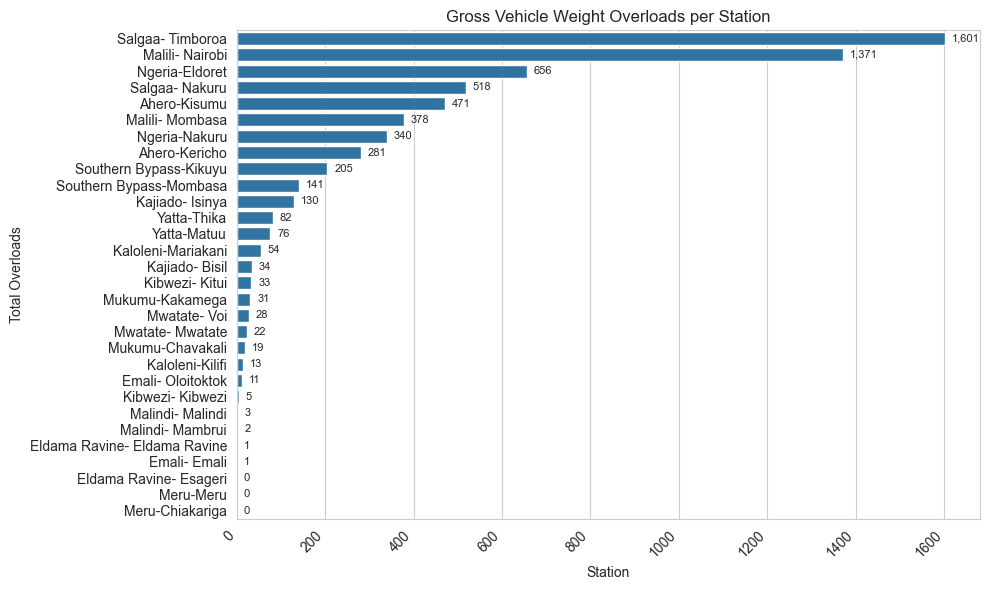

In [145]:
total_compliance = table.loc[table["Station"] == "TOTAL", "Compliance"].iloc[0]

# summary_text
summary_text = f"""
    4.1 Gross Vehicle Overloads per Station per Direction and Compliance
    • {highest["Station"].title()} recorded the highest number of gross vehicle weight overloads, totaling {int(highest['Total Overloads']):,}, followed by {second_highest["Station"].title()} with {int(second_highest["Total Overloads"]):,}.
    • On average, the compliance rate was {total_compliance}
"""
print(summary_text)

plot_data = table[table["Station"] != "TOTAL"].copy()

plot_data["Total Overloads"] = (
    plot_data["Total Overloads"].astype(str) .str.replace("," , "").astype(int)
    )

plot_data = plot_data.sort_values(by="Total Overloads", ascending=False)

# Plot bar chart
plt.figure(figsize=(10,6))
ax = sns.barplot(data=plot_data, y="Station", x="Total Overloads")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left', va='center',
                fontsize=8,
                xytext=(5,0),
                textcoords='offset points')

plt.title("Gross Vehicle Weight Overloads per Station")
plt.xlabel("Station")
plt.ylabel("Total Overloads")
plt.xticks(rotation=45, ha="right")

# Add figure caption 
fig.text(
    0.5,
    -0.20,
    r"$\bf{Figure\ 5:}$ Gross Vehicle Weight Overloads per Station",
    ha='center',
    fontsize=11
)

plt.tight_layout()

plt.savefig("gvw.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


    4.2 Axle Vehicle Overloads per Station per Direction

     This section of the report focuses on the vehicles cautioned for axle overloads.
    • A total of 12,439 vehicles were cautioned for axle weight overloading.
    • Malili- Nairobi had the highest number of warnings, totaling 2,322 vehicles followed by Salgaa- Timboroa with 2,206.



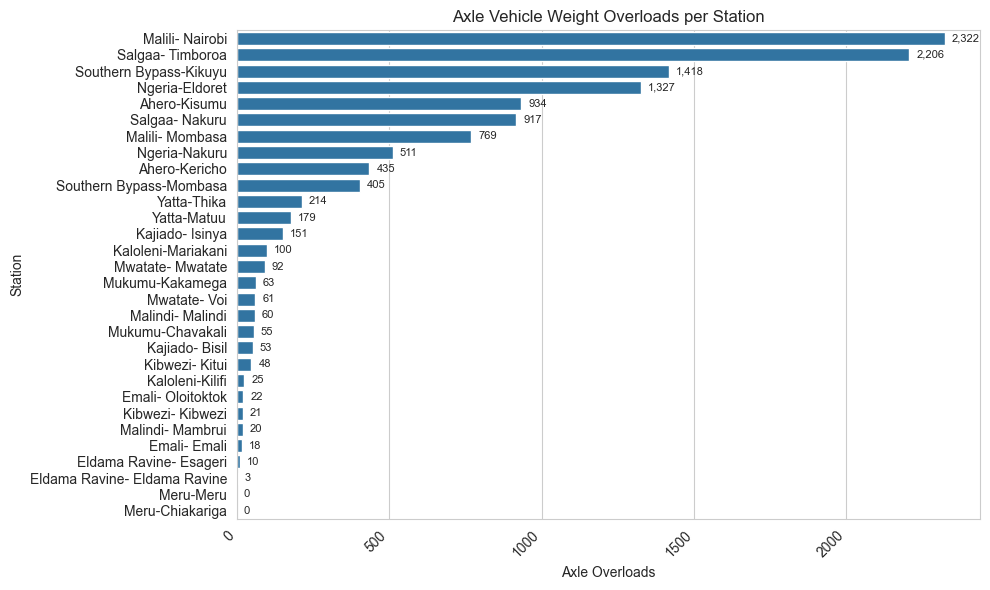

In [146]:
table["AVW Overloads"] = (
    table["AVW Overloads"]
    .astype(str)
    .str.replace("," , "")
    .astype(int)
)

AVW_Overloads = table.loc[table["Station"] == "TOTAL" , "AVW Overloads"].values[0]
data_rows = table[table["Station"] != "TOTAL"]
data_rows = data_rows.sort_values(by="AVW Overloads", ascending=False)

highest = data_rows.iloc[0]
second_highest = data_rows.iloc[1]

# summary_text
summary_text = f"""
    4.2 Axle Vehicle Overloads per Station per Direction\n
     This section of the report focuses on the vehicles cautioned for axle overloads.
    • A total of {AVW_Overloads:,} vehicles were cautioned for axle weight overloading.
    • {highest["Station"].title()} had the highest number of warnings, totaling {int(highest['AVW Overloads']):,} vehicles followed by {second_highest["Station"].title()} with {int(second_highest["AVW Overloads"]):,}.
"""
print(summary_text)

plot_data = table[table["Station"] != "TOTAL"].copy()

plot_data["AVW Overloads"] = (
    plot_data["AVW Overloads"].astype(str) .str.replace("," , "").astype(int)
    )

plot_data = plot_data.sort_values(by="AVW Overloads", ascending=False)


# Plot bar chart
plt.figure(figsize=(10,6))
ax = sns.barplot(data=plot_data, y="Station", x="AVW Overloads")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left', va='center',
                fontsize=8,
                xytext=(5,0),
                textcoords='offset points')

plt.title("Axle Vehicle Weight Overloads per Station")
plt.xlabel("Axle Overloads")
plt.ylabel("Station")
plt.xticks(rotation=45, ha="right")

# Add figure caption 
fig.text(
    0.5,
    -0.20,
    r"$\bf{Figure\ 6:}$ Axle Vehicle Weight Overloads per Station",
    ha='center',
    fontsize=11
)

plt.tight_layout()

plt.savefig("avw.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


    4.3 Tagged Vehicles (GVW >2000)

     This section of the report examines vehicles that recorded gross vehicle weight exceeding 2000 kg and how they were distributed across the stations.
    • A total of 3,068 vehicles were tagged for overloading.
    • Salgaa- Timboroa had the highest number of tags, totaling 1,003.
    • 7 stations had no tagged vehicles (Kibwezi- Kibwezi, Malindi- Mambrui, Eldama Ravine- Eldama Ravine, Emali- Emali, Eldama Ravine- Esageri, Meru-Meru, Meru-Chiakariga).



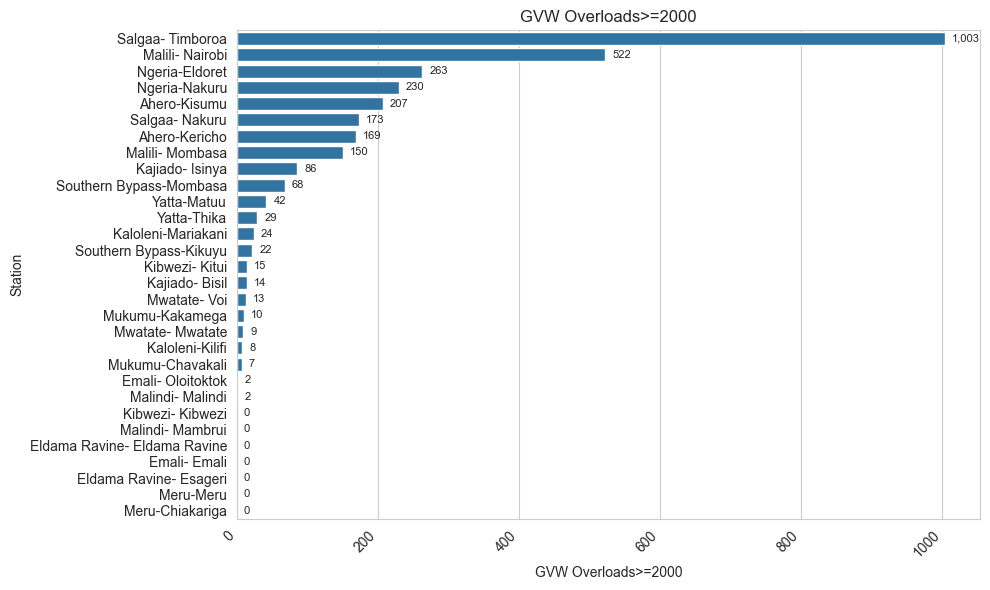

In [147]:
table["GVW Overloads>=2000"] = (
    table["GVW Overloads>=2000"]
    .astype(str)
    .str.replace("," , "")
    .astype(int)
)

GVW_Overloads_2000 = table.loc[table["Station"] == "TOTAL" , "GVW Overloads>=2000"].values[0]
data_rows = table[table["Station"] != "TOTAL"]
data_rows = data_rows.sort_values(by="GVW Overloads>=2000", ascending=False)

highest = data_rows.iloc[0]
second_highest = data_rows.iloc[1] if len(data_rows) > 1 else None
Stations_without_overloads = table[
    (table["Station"]!= "TOTAL") & 
    (table["GVW Overloads>=2000"] == 0)
]["Station"]

stations_list = ", ".join(Stations_without_overloads.tolist())
count_no_overload = len(Stations_without_overloads)
# summary_text
summary_text = f"""
    4.3 Tagged Vehicles (GVW >2000)\n
     This section of the report examines vehicles that recorded gross vehicle weight exceeding 2000 kg and how they were distributed across the stations.
    • A total of {GVW_Overloads_2000:,} vehicles were tagged for overloading.
    • {highest["Station"].title()} had the highest number of tags, totaling {int(highest['GVW Overloads>=2000']):,}.
    • {count_no_overload} stations had no tagged vehicles ({stations_list}).
"""
print(summary_text)

plot_data = table[table["Station"] != "TOTAL"].copy()

plot_data["GVW Overloads>=2000"] = (
    plot_data["GVW Overloads>=2000"].astype(str) .str.replace("," , "").astype(int)
    )

plot_data = plot_data.sort_values(by="GVW Overloads>=2000", ascending=False)


# Plot bar chart
plt.figure(figsize=(10,6))
ax = sns.barplot(data=plot_data, y="Station", x="GVW Overloads>=2000")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left', va='center',
                fontsize=8,
                xytext=(5,0),
                textcoords='offset points')

plt.title("GVW Overloads>=2000")
plt.xlabel("GVW Overloads>=2000")
plt.ylabel("Station")
plt.xticks(rotation=45, ha="right")

# Add figure caption 
fig.text(
    0.5,
    -0.20,
    r"$\bf{Figure\ 7:}$ GVW Overloads > 2000 KGS per Direction",
    ha='center',
    fontsize=11
)

plt.tight_layout()

plt.savefig("tags.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [148]:
# Check sheet names and preview data
print(all_sheets["Sheet1"].head())

       TICKET NO           DATE TIME        STATION REGISTRATION  \
0  VIRT597356864 2026-01-10 15:27:27  AHERO-KERICHO     KDS582V    
1   TAG597303620 2026-01-10 08:09:19  AHERO-KERICHO   UNKNOWN_E    
2   TAG597403972 2026-01-10 22:24:33  AHERO-KERICHO   UNKNOWN_E    
3   TAG597358404 2026-01-10 15:37:51  AHERO-KERICHO   UNKNOWN_E    
4  VIRT597307462 2026-01-10 08:49:37  AHERO-KERICHO     KDT210T    

  REGISTRATION BACK AXLE CONFIG   SPEED  AXLE 1 [KG]  PERM. [KG]  AXLE 2 [KG]  \
0           ZG2703     6*SWWWWW  41km/h       4778.0      8000.0      10452.0   
1        UNKNOWN_E           2A  55km/h       9350.0      8000.0      19958.0   
2        UNKNOWN_E           3A  60km/h       7708.0      8000.0      13992.0   
3        UNKNOWN_E           2A  56km/h       8138.0      8000.0      19750.0   
4        UNKNOWN_E           6G  40km/h       6687.0      8000.0       8949.0   

   PERM. [KG].1  AXLE 3 [KG]  PERM. [KG].2  AXLE 4 [KG]  PERM. [KG].3  \
0        7500.0       8830.0   

In [149]:
df2 = all_sheets["Sheet1"]

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3068 entries, 0 to 3067
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   TICKET NO            3068 non-null   object        
 1   DATE TIME            3068 non-null   datetime64[ns]
 2   STATION              3068 non-null   object        
 3   REGISTRATION         3068 non-null   object        
 4   REGISTRATION BACK    3068 non-null   object        
 5   AXLE CONFIG          3068 non-null   object        
 6   SPEED                3068 non-null   object        
 7   AXLE 1 [KG]          3068 non-null   float64       
 8   PERM. [KG]           3068 non-null   float64       
 9   AXLE 2 [KG]          3068 non-null   float64       
 10  PERM. [KG].1         3068 non-null   float64       
 11  AXLE 3 [KG]          3068 non-null   float64       
 12  PERM. [KG].2         3068 non-null   float64       
 13  AXLE 4 [KG]          3068 non-nul

In [150]:
# Clean data
print(df2.isna().sum())
print()

TICKET NO              0
DATE TIME              0
STATION                0
REGISTRATION           0
REGISTRATION BACK      0
AXLE CONFIG            0
SPEED                  0
AXLE 1 [KG]            0
PERM. [KG]             0
AXLE 2 [KG]            0
PERM. [KG].1           0
AXLE 3 [KG]            0
PERM. [KG].2           0
AXLE 4 [KG]            0
PERM. [KG].3           0
AXLE 5 [KG]            0
PERM. [KG].4           0
AXLE 6 [KG]            0
PERM. [KG].5           0
AXLE 7 [KG]            0
PERM. [KG].6           0
AXLE 8 [KG]            0
PERM. [KG].7           0
TOTAL WEIGHT           0
GVW PERM. [KG]         0
EXCESS GVW [KG]        0
EXCESS AVW [KG]        0
LEFTSIDE LOAD [KG]     0
RIGHTSIDE LOAD [KG]    0
SIDE VARIANCE[KG]      0
% GVW OVERLOAD         0
% AVW OVERLOAD         0
dtype: int64



In [151]:
# Clean columns
df2.columns = df2.columns.str.strip().str.replace(" " , "_")

type(df2)

pandas.core.frame.DataFrame

In [152]:
summary = df2["AXLE_CONFIG"].value_counts().reset_index()
summary.columns = ['Axle Configuration', 'No of Tags']

# Calculate percentage
summary['Relative Count(%)'] = (
    summary['No of Tags'] / summary['No of Tags'].sum() * 100
).round(2)

summary['Relative Count(%)'] = summary['Relative Count(%)'].astype(str) + '%'

# Sort
summary = summary.sort_values(by='No of Tags', ascending=False).reset_index(drop=True)

# Add Total row
grand_total = pd.DataFrame({
    'Axle Configuration': ['Grand Total'],
    'No of Tags': [summary['No of Tags'].sum()],
    'Relative Count(%)': [100.00]
})



most_tagged = summary.loc[0, 'Axle Configuration']
tag_value = summary.loc[0, 'No of Tags']
tag_percentage = f"{summary.loc[0, 'Relative Count(%)']}"

summary = pd.concat([summary, grand_total], ignore_index=True)

# Summary text
summary_text = f"""
4.4 GVW > 2000 Overloads per Axle Configuration
Table 5 contains the distribution of overloads per Axle configuration. Overall:
   • Most tagged vehicles were {most_tagged} trucks ({tag_value:,}) which accounted for {tag_percentage}.

Table 5: GVW > 2000 Overloads per Axle Configuration
"""
print(summary_text)
print(summary.to_string(index=False))




4.4 GVW > 2000 Overloads per Axle Configuration
Table 5 contains the distribution of overloads per Axle configuration. Overall:
   • Most tagged vehicles were 6G trucks (2,353) which accounted for 76.69%.

Table 5: GVW > 2000 Overloads per Axle Configuration

Axle Configuration  No of Tags Relative Count(%)
                6G        2353            76.69%
                2A         256             8.34%
                3A         157             5.12%
              2*SD         122             3.98%
                6A          53             1.73%
          6*SWWWWW          42             1.37%
               7A*          23             0.75%
                3*          21             0.68%
                4A          20             0.65%
                5D           7             0.23%
              2*SS           5             0.16%
                6*           2             0.07%
          6*SSDWWW           1             0.03%
                2*           1             0.03%
    

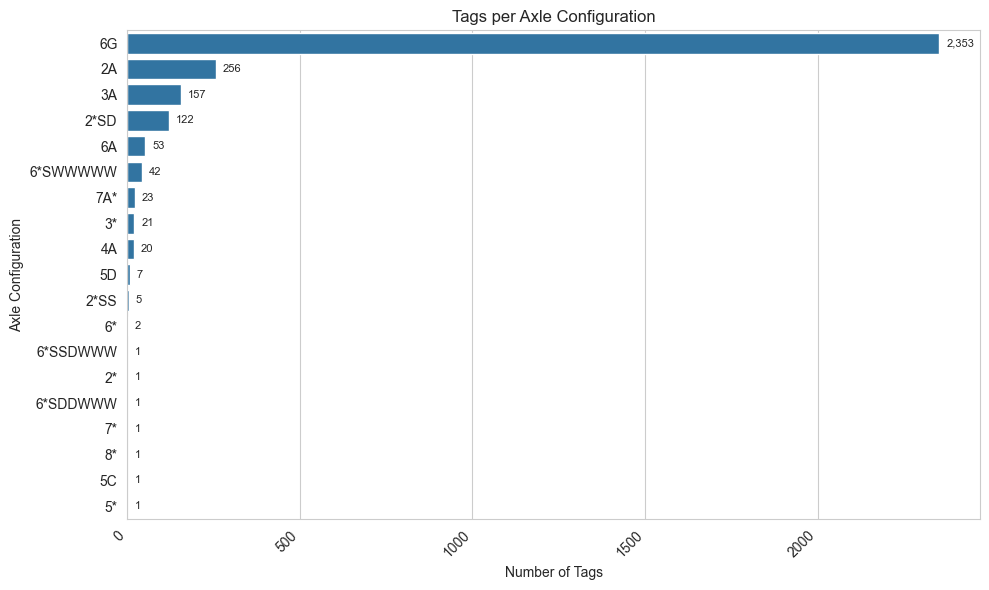

In [153]:
plot_data = summary[summary["Axle Configuration"] != "Grand Total"].copy()

plot_data["No of Tags"] = (
    plot_data["No of Tags"].astype(str) .str.replace("," , "").astype(int)
    )

# Plot bar chart
plt.figure(figsize=(10,6))
ax = sns.barplot(data=plot_data, y="Axle Configuration", x="No of Tags")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left', va='center',
                fontsize=8,
                xytext=(5,0),
                textcoords='offset points')

plt.title("Tags per Axle Configuration")
plt.xlabel("Number of Tags")
plt.ylabel("Axle Configuration")
plt.xticks(rotation=45, ha="right")

# Add figure caption 
fig.text(
    0.5,
    -0.20,
    r"$\bf{Figure\ 7:}$ Overloads per Vehicle Configuration",
    ha='center',
    fontsize=11
)

plt.tight_layout()

plt.savefig("tags_axle.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [154]:
# CLean columns
df2.columns = df2.columns.str.strip()
df2["REGISTRATION"] = df2["REGISTRATION"].fillna("").astype(str).str.upper().str.strip()

df2["Station"] = df2["STATION"].str.split("-").str[0].str.strip()
df2["Station"] = df2["Station"].str.lower().str.title()

# Flag unknowns
df2["is_unknown"] = df2["REGISTRATION"].str.startswith("UNKNOWN").astype(int)

# Group by station 
summary = df2.groupby("Station").agg(
    Unknown_Tags=("is_unknown", "sum"),
    Total_Tags=("REGISTRATION", "count")
).reset_index()

summary["Unknown_Tags"] = pd.to_numeric(summary["Unknown_Tags"], errors="coerce")
summary["Total_Tags"] = pd.to_numeric(summary["Total_Tags"], errors="coerce")

# Calculate percentage
summary["%Unknown per Station"] = (
    summary["Unknown_Tags"] / summary["Total_Tags"] * 100
).round(2)

# Add Total row
total_row = pd.DataFrame({
    "Station": ["TOTAL"],
    "Unknown_Tags": [summary["Unknown_Tags"].sum()],
    "Total_Tags": [summary["Total_Tags"].sum()]
})

# Calculate Total percentage
total_row["%Unknown per Station"] = (
    total_row["Unknown_Tags"] / total_row["Total_Tags"] * 100
).round(2)

final_table = pd.concat([summary, total_row], ignore_index=True)

# Rename columns(
final_table = final_table.rename(columns={
    "Unknown_Tags": "Unknown Tags",
    "Total_Tags": "Total Tags"
})

final_table["%Unknown per Station"] = (
    final_table["%Unknown per Station"].astype(str) + "%"
)
number_of_unknown_tags = summary["Unknown_Tags"].sum()

summary_text = f"""
4.5 Unknown Tagged Vehicles per Station
A record of {number_of_unknown_tags} tagged vehicles with unidentified plates were reported acrooss the stations. This table shows the frequency of total tags and unknown tags per station.

Table 6: Unknown Tags per Station
"""

print(summary_text)
print(final_table.to_string(index=False))


4.5 Unknown Tagged Vehicles per Station
A record of 429 tagged vehicles with unidentified plates were reported acrooss the stations. This table shows the frequency of total tags and unknown tags per station.

Table 6: Unknown Tags per Station

        Station  Unknown Tags  Total Tags %Unknown per Station
          Ahero            73         376               19.41%
          Emali             1           2                50.0%
        Kajiado            10         100                10.0%
       Kaloleni             5          32               15.62%
        Kibwezi             0          15                 0.0%
         Malili           103         672               15.33%
        Malindi             0           2                 0.0%
         Mukumu            13          17               76.47%
        Mwatate             3          22               13.64%
         Ngeria            38         493                7.71%
         Salgaa           132        1176               11.22%

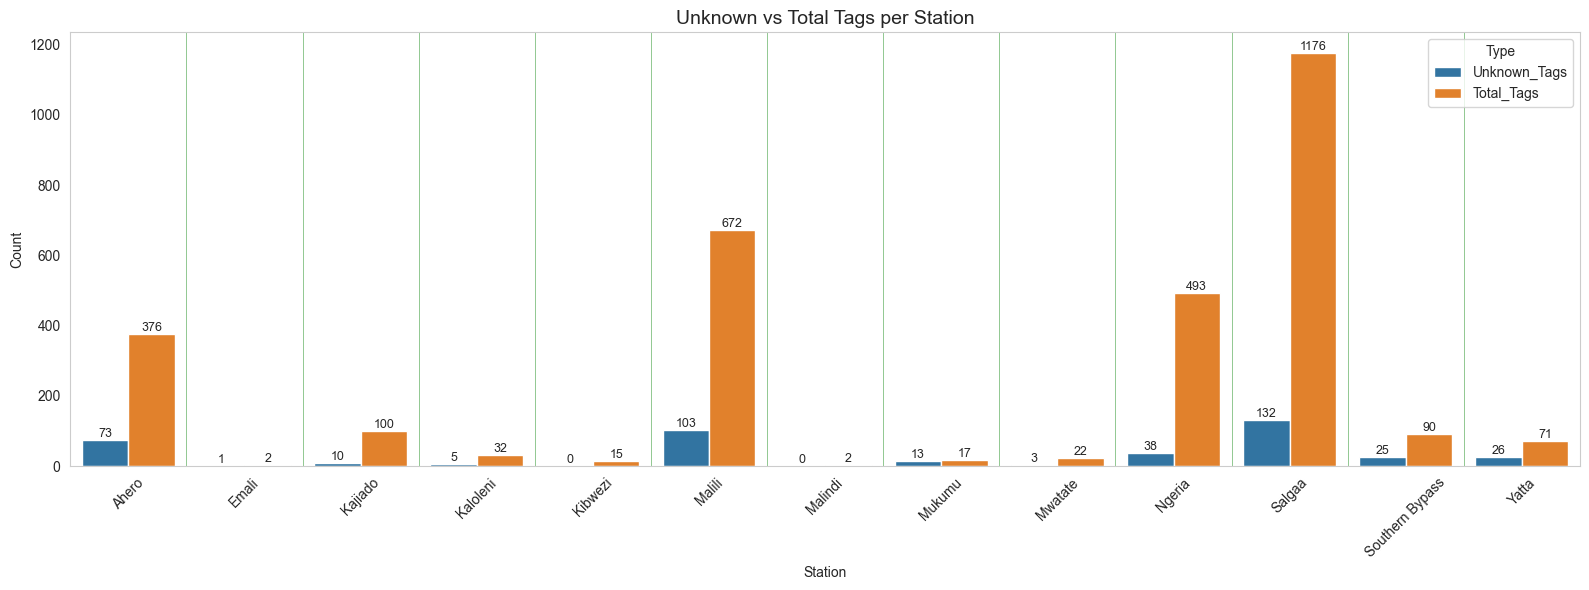

In [155]:
# Convert to long format 
df2_long = summary.melt(
    id_vars="Station",
    value_vars=["Unknown_Tags", "Total_Tags"],
    var_name="Type",
    value_name="Count"
)

# Plot style
sns.set_style("whitegrid")

plt.figure(figsize=(16,6))

# Seaborn barplot
ax = sns.barplot(
    data=df2_long,
    x="Station",
    y="Count",
    hue="Type"
)

# Rotate labels
plt.xticks(rotation=45)

# Title
plt.title("Unknown vs Total Tags per Station", fontsize=14)

# Vertical gridlines
ax.grid(axis='y', visible=False)

for i in range(len(summary) + 1):
    ax.axvline(i -0.5, color='green', linewidth=0.6, alpha=0.5)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=9)

plt.tight_layout()

plt.savefig("unknown_tags.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()